# End-to-End and Foundation-Model Driving: What Changes for Safety

**Module 06 · AI Safety (ISO/PAS 8800)** · Notebook 7 of 8

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/06_AI_Safety_ISO_PAS_8800/07_end_to_end_and_foundation_models.ipynb) [![Run in browser](https://img.shields.io/badge/Run_in_browser-no_account-0072B2)](https://milinpatel07.github.io/Autonomous-Driving_AI-Safety-and-Security/lite/notebooks/index.html?path=06_AI_Safety_ISO_PAS_8800/07_end_to_end_and_foundation_models.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Advanced | [AI safety standards](01_ai_safety_standards.ipynb), [Uncertainty types](02_uncertainty_types.ipynb), [Criticality metrics and RSS](../04_SOTIF_ISO21448/05_criticality_metrics_and_rss.ipynb); supervised learning basics | ISO/PAS 8800:2024, ISO 21448:2022, ISO/TS 5083:2025, UL 4600 (3rd ed., 2023) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

After this notebook you will be able to:

1. Distinguish **modular**, **monolithic end-to-end**, **modular end-to-end**, **vision-language(-action)** and **world-model** approaches to automated driving, using verified and dated examples.
2. Explain the safety-relevant failure modes these approaches add or sharpen: **compounding error under covariate shift**, **causal confusion**, **shortcut learning**, **distribution shift**, **hallucination** and the **loss of intermediate interfaces** for monitoring.
3. Train a small **imitation-learning driving policy** on real lead-vehicle speed profiles from NGSIM and **demonstrate** behaviour-cloning failure, its repair with **DAgger**, and **causal confusion** from a nuisance input.
4. Wrap a learned policy with an **RSS-based runtime shield** and a lateral **Simplex** monitor, and quantify what it fixes and what it cannot.
5. State what evidence **ISO/PAS 8800**, **ISO 21448** and **UL 4600** would require for a learned driving policy, and name the main open problems as of October 2026.

## 1. From modular stacks to driving foundation models

| Approach | Idea | Verified examples (date) | Interfaces a safety engineer can inspect |
|---|---|---|---|
| **Modular pipeline** | Separately specified and tested perception, prediction, planning and control | The reference architecture of most deployed systems; survey: Paden et al. (2016) | Object lists, tracks, predicted trajectories, planned trajectory |
| **Monolithic end-to-end** (behaviour cloning) | One network maps sensor input directly to control | ALVINN, a three-layer network steering CMU's NAVLAB (Pomerleau, NIPS 1988); NVIDIA's camera-to-steering CNN (Bojarski et al., arXiv, April 2016) | Only the output command |
| **Modular end-to-end** ("planning-oriented") | Differentiable perception, prediction and planning modules trained jointly for the planning objective | UniAD (Hu et al., CVPR 2023, best paper award); VAD (Jiang et al., ICCV 2023) | Intermediate outputs exist, but they are optimised for planning, not specified and validated as interfaces |
| **Vision-language (-action) models** | A (multimodal) language model describes, reasons about and, in VLA models, outputs the driving action | DriveLM (Sima et al., ECCV 2024); DriveVLM (Tian et al., arXiv, February 2024); EMMA (Hwang et al., Waymo, arXiv October 2024, TMLR); Alpamayo-R1 (NVIDIA, arXiv October 2025) | Natural-language explanations, which are not guaranteed to reflect how the action was computed |
| **World models** | A generative model of how the scene (or sensor data) evolves, used for simulation, data generation and evaluation | GAIA-1 (Hu et al., Wayve, arXiv, September 2023) | Generated scenarios, whose fidelity must itself be validated |

The trend is from hand-specified interfaces towards models that learn their own internal representations. That changes the safety engineering problem. In a modular stack a requirement such as "detect pedestrians within 50 m with recall ≥ X" can be tested on the perception output, and a monitor such as RSS can be fed with the object list. In an end-to-end model the same requirement has no obvious place to be verified.

### 1.1 Industry statements (claims by the companies, not independently verified)

| Company, date, source | Statement |
|---|---|
| Tesla, FSD Beta v12 release notes, 24 December 2023 (as reproduced by *Not a Tesla App*) | "FSD Beta v12 upgrades the city-streets driving stack to a single end-to-end neural network trained on millions of video clips, replacing over 300k lines of explicit C++ code." |
| Wayve, blog "LINGO-2: Driving with Natural Language", 17 April 2024 | Describes LINGO-2 as "the first closed-loop vision-language-action driving model (VLAM) tested on public roads". |
| NVIDIA, arXiv:2511.00088, 30 October 2025 | Alpamayo-R1: a vision-language-action model combining a reasoning VLM (Cosmos-Reason) with a diffusion-based trajectory decoder; the authors report "real-time performance (99 ms latency)" in on-vehicle road tests. |
| Waymo, blog "Demonstrably Safe AI for Autonomous Driving", 9 December 2025 | The Waymo Foundation Model is described as powering the Driver, the Simulator and the Critic; it produces "compact, materialized structured representations like objects, semantic attributes, and roadgraph elements", and the Driver uses "a separate and rigorous onboard validation layer" that verifies the generated trajectories. |

Note what the last statement implies: even a company that trains a large learned driver keeps explicit structured outputs and a separate validation layer. That is the architecture this notebook builds in miniature in Section 7.

## 2. What changes for safety: failure modes

| Failure mode | Mechanism | Evidence in the literature | Where you see it below |
|---|---|---|---|
| **Compounding error (covariate shift)** | A policy trained only on the expert's state distribution makes small errors, reaches states the expert never visited, and errs more there. For behaviour cloning the expected cost can grow quadratically with the task horizon; DAgger reduces this to linear by collecting expert labels on the learner's own states (Ross et al., 2011). | ALVINN already needed synthetic off-centre training images for this reason (Pomerleau, 1988) | Section 4–5 |
| **Causal confusion** | The policy relies on an input that is correlated with the expert's action in the data but is not its cause; *more* information can make it *worse* (de Haan et al., 2019). In driving, cloned policies learn that "not moving" predicts "not moving" (the inertia problem; Codevilla et al., 2019). | | Section 6 |
| **Shortcut learning** | Networks pick the easiest decision rule that fits the benchmark (Geirhos et al., 2020). On the nuScenes open-loop planning benchmark, ego-status-only baselines rival full perception-based planners (Zhai et al., 2023; Li et al., 2024): the metric rewards extrapolating the ego's own motion. | | Discussion |
| **Distribution shift** | Inputs outside the training distribution (new city, weather, road geometry) give confident but wrong outputs. | Module 02, [OOD detection](../02_Failures_and_Robustness/03_out_of_distribution_detection.ipynb) | Section 7.2 |
| **Hallucination** | Language and vision-language models generate fluent statements about objects or causes that are not present in the input (object hallucination: Rohrbach et al., 2018; survey: Ji et al., 2023). A VLA explanation can be plausible and wrong. | | Discussion |
| **No intermediate interface** | Runtime monitors (RSS, plausibility checks) need object-level inputs; an end-to-end model may not expose them. | Waymo's statement in 1.1 | Section 7 |
| **Open-loop evaluation** | Displacement error against logged trajectories says little about closed-loop driving; on nuPlan, open-loop and closed-loop scores are poorly aligned (Dauner et al., 2023). NAVSIM proposes non-reactive simulation-based metrics as a compromise (Dauner et al., 2024). | | Sections 5–6 compare offline and closed-loop metrics |

The hands-on part reproduces the first two mechanisms and a runtime shield in a deliberately small setting, where every number can be traced.

## 3. Data, simulator and expert

**Data and licence.** The lead vehicle's speed profile in every episode is a **real** 30 s speed trace of a vehicle on US-101 (NGSIM, Los Angeles, 15 June 2005, 08:20, congested traffic), smoothed over 1 s. Half of the vehicles are used for training, the other half for testing. NGSIM is public-domain US government data (feet and ft/s, converted to SI).

**Simulator.** The ego is a kinematic vehicle in road-aligned coordinates: lateral offset $e$, heading error $\psi$, speed $v$, gap $g$ to the lead. Per 0.1 s step: $\dot e = v \sin\psi$, $\dot\psi = v(\kappa_{\text{cmd}} - \kappa_{\text{road}})$, $\dot v = a$, $\dot g = v_{\text{lead}} - v$. Actions are acceleration $a$ and path curvature $\kappa_{\text{cmd}}$, with actuation noise.

> **Illustrative data:** the road curvature profiles (|κ| ≤ 0.004 1/m, i.e. radii of 250 m and more) and the noise levels are synthetic, chosen for teaching; the lead speeds are real.

**Expert.** The demonstrator is a well-behaved driver model: the Intelligent Driver Model for car following (Treiber et al., 2000) and a critically damped lateral feedback law. It sees the true state. The **learner** sees perception outputs with noise (σ = 1.5 m on the gap, 0.7 m/s on the relative speed, 5 cm on the lateral offset), as a real camera-based policy would.

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D
from avsafety.sotif import rss_safe_longitudinal_distance

import math
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

warnings.filterwarnings("ignore", category=ConvergenceWarning)
T0 = time.time()
rng = np.random.default_rng(42)
FT = 0.3048
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "red": "#D55E00", "purple": "#CC79A7", "black": "#000000"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print(D.attribution("NGSIM"))

Data: US DOT Next Generation Simulation (NGSIM) vehicle trajectories, public domain, https://data.transportation.gov/d/8ect-6jqj


In [2]:
T_START, WINDOW_MS = 1118848800000, 50_000          # 15 June 2005 08:20:00 PDT, 50 s
try:
    raw = D.ngsim("us-101", where=f"global_time >= {T_START} AND global_time < {T_START + WINDOW_MS}",
                  select="vehicle_id,global_time,local_x,local_y,v_length,v_width,v_vel,lane_id")
except D.DataUnavailable as exc:
    raise SystemExit(f"NGSIM could not be downloaded ({exc}); the lead-vehicle profiles are needed.")
raw = raw.sort_values(["vehicle_id", "global_time"])
profiles = []
for vid, g in raw[raw.lane_id <= 5].groupby("vehicle_id"):
    if len(g) >= 300 and np.all(np.diff(g.global_time.to_numpy()) == 100):
        v = g.v_vel.to_numpy() * FT
        v = np.convolve(np.r_[np.full(5, v[0]), v, np.full(5, v[-1])], np.ones(11) / 11, mode="valid")
        profiles.append(v[:300])
profiles = np.array(profiles)
order = rng.permutation(len(profiles))
TRAIN_P, TEST_P = profiles[order[: len(order) // 2]], profiles[order[len(order) // 2:]]
print(f"{len(profiles)} real 30 s lead-speed profiles: {len(TRAIN_P)} for training, {len(TEST_P)} for testing. "
      f"Speeds {profiles.min():.1f}-{profiles.max():.1f} m/s; strongest lead deceleration "
      f"{-np.diff(profiles, axis=1).min() / 0.1:.1f} m/s^2.")

122 real 30 s lead-speed profiles: 61 for training, 61 for testing. Speeds 1.7-17.7 m/s; strongest lead deceleration 3.8 m/s^2.


In [3]:
DT, N_STEPS = 0.1, 300
A_MIN, A_MAX, K_MAX = -8.0, 2.0, 0.05          # physical limits: deceleration, acceleration [m/s^2], curvature [1/m]
LANE_HALF = 1.75 - 0.9                          # |e| at which a wheel of a 1.8 m wide car touches a 3.5 m lane's marking
NOISE = np.array([0.1, 0.0005])                 # actuation noise: acceleration [m/s^2], curvature [1/m]
OBS_NOISE = np.array([0.05, 0.002, 0.0, 0.2, 1.5, 0.7])   # learner's perception noise on (e, psi, kappa, v, gap, dv)
RSS = dict(rho=0.5, a_max_accel=2.0, b_min_brake=4.0, b_max_brake=8.0)   # avsafety.sotif defaults

def rss_dmin(v_rear, v_front, rho=0.5, a_max_accel=2.0, b_min_brake=4.0, b_max_brake=8.0):
    # vectorised copy of avsafety.sotif.rss_safe_longitudinal_distance
    v_after = v_rear + rho * a_max_accel
    return np.maximum(v_rear * rho + 0.5 * a_max_accel * rho**2 + v_after**2 / (2 * b_min_brake)
                      - v_front**2 / (2 * b_max_brake), 0.0)

_vv = np.linspace(0, 30, 16)
assert all(abs(rss_dmin(x, y) - rss_safe_longitudinal_distance(x, y)) < 1e-9 for x in _vv for y in _vv)

def road_curvature(seed, k_amp=0.004, n=N_STEPS):
    # Synthetic road: smooth random curvature profile with |kappa| <= k_amp
    r = np.random.default_rng(seed)
    t = np.arange(n) * DT
    k = sum(r.uniform(-1, 1) * np.sin(2 * np.pi * t / r.uniform(8, 25) + r.uniform(0, 6.3)) for _ in range(3))
    return k_amp * k / max(np.abs(k).max(), 1e-9)

def idm(v, gap, v_lead, v0=20.0, a=1.5, b=2.0, T=1.2, s0=2.0):
    s_star = s0 + v * T + v * (v - v_lead) / (2 * math.sqrt(a * b))
    return a * (1 - (v / v0)**4 - (np.maximum(s_star, 0.0) / np.maximum(gap, 0.1))**2)

def expert(O):
    # Demonstrator: IDM car following + critically damped lateral feedback. O columns: e, psi, kappa, v, gap, dv
    e, psi, kap, v, gap, dv = (O[:, i] for i in range(6))
    acc = np.clip(idm(v, gap, v + dv), A_MIN, A_MAX)
    vv = np.maximum(v, 5.0)
    return np.c_[acc, np.clip(kap - (0.5 * e + 1.4 * vv * psi) / vv**2, -K_MAX, K_MAX)]

def rollout(policy, lead_v, kappa, with_prev=False, shield=None, beta=0.0, seed=0, lat_expert=False):
    # Closed-loop simulation of one episode per row of lead_v / kappa, all in parallel.
    # policy(O) -> (N, 2) actions; beta: probability per step that the expert acts instead (DAgger mixing);
    # shield(O, A) -> (A, overridden); lat_expert: the expert steers (longitudinal-only experiments).
    r = np.random.default_rng(seed)
    N = len(lead_v)
    e, psi, v = np.zeros(N), np.zeros(N), lead_v[:, 0].copy()
    gap = 2.0 + 1.5 * v
    prev = np.c_[np.zeros(N), kappa[:, 0]]
    alive = np.ones(N, bool)
    keys = ["e", "v", "gap", "vl", "acc", "rss_ok", "override"]
    H = {k: np.full((N, N_STEPS - 1), np.nan) for k in keys}
    obs, labels = [], []
    for k in range(N_STEPS - 1):
        vl, kap = lead_v[:, k], kappa[:, k]
        truth = np.c_[e, psi, kap, v, gap, vl - v]
        A_exp = expert(truth)                                   # the expert sees the true state
        O = truth + r.normal(0, 1, truth.shape) * OBS_NOISE    # the learner sees noisy perception outputs
        if with_prev:
            O = np.c_[O, prev[:, 0]]                            # nuisance input: own previous acceleration
        A = A_exp.copy() if policy is expert else policy(O)
        if lat_expert:
            A = np.c_[A[:, 0], A_exp[:, 1]]
        if beta > 0:
            A = np.where((r.random(N) < beta)[:, None], A_exp, A)
        over = np.zeros(N)
        if shield is not None:
            A, over = shield(O, A)
        A = A + r.normal(0, 1, (N, 2)) * NOISE
        A = np.c_[np.clip(A[:, 0], A_MIN, A_MAX), np.clip(A[:, 1], -K_MAX, K_MAX)]
        for key, val in zip(keys, [e, v, gap, vl, A[:, 0], gap >= rss_dmin(v, vl), over]):
            H[key][:, k] = np.where(alive, val, np.nan)
        obs.append(O[alive]); labels.append(A_exp[alive])
        v_new = np.maximum(v + A[:, 0] * DT, 0.0)
        ds = 0.5 * (v + v_new) * DT
        e = np.where(alive, e + ds * np.sin(psi), e)
        psi = np.where(alive, psi + ds * (A[:, 1] - kap), psi)
        gap = np.where(alive, gap + 0.5 * (lead_v[:, k] + lead_v[:, k + 1]) * DT - ds, gap)
        v = np.where(alive, v_new, v)
        prev = A
        alive &= (gap > 0) & (np.abs(e) <= 3.5)
    H["collision"], H["departure"] = gap <= 0, np.abs(e) > 3.5
    H["obs"], H["labels"] = np.vstack(obs), np.vstack(labels)
    return H

def metrics(H):
    ttc = np.where(H["v"] > H["vl"], H["gap"] / np.maximum(H["v"] - H["vl"], 1e-9), np.inf)
    min_ttc = np.nanmin(np.where(np.isnan(H["gap"]), np.inf, ttc), axis=1)
    return {"collisions [%]": 100 * H["collision"].mean(),
            "road departures [%]": 100 * H["departure"].mean(),
            "episodes leaving the lane [%]": 100 * (np.nanmax(np.abs(H["e"]), axis=1) > LANE_HALF).mean(),
            "mean max |e| [m]": np.nanmean(np.nanmax(np.abs(H["e"]), axis=1)),
            "episodes with min TTC < 1.5 s [%]": 100 * (min_ttc < 1.5).mean(),
            "time RSS-unsafe [%]": 100 * (1 - np.nanmean(H["rss_ok"])),
            "longitudinal overrides [%]": 100 * np.nanmean(np.where(np.isnan(H["override"]), np.nan, H["override"] % 2 == 1)),
            "lateral overrides [%]": 100 * np.nanmean(np.where(np.isnan(H["override"]), np.nan, H["override"] >= 2))}

K_TRAIN = np.array([road_curvature(1000 + i) for i in range(len(TRAIN_P))])
K_TEST = np.array([road_curvature(5000 + i) for i in range(len(TEST_P))])
expert_test = metrics(rollout(expert, TEST_P, K_TEST, seed=2))
print("Expert on the test episodes:", {k: round(float(x), 2) for k, x in expert_test.items()})

Expert on the test episodes: {'collisions [%]': 0.0, 'road departures [%]': 0.0, 'episodes leaving the lane [%]': 0.0, 'mean max |e| [m]': 0.04, 'episodes with min TTC < 1.5 s [%]': 0.0, 'time RSS-unsafe [%]': 30.64, 'longitudinal overrides [%]': 0.0, 'lateral overrides [%]': 0.0}


The expert never collides and never leaves its lane. It still spends a noticeable fraction of the time inside the RSS distance: IDM with a 1.2 s time gap follows more closely than RSS's default worst-case assumptions allow, as do the real drivers analysed in [07/02](../07_Runtime_Assurance_and_Operations/02_safe_motion_planning_and_fallback.ipynb). "Imitating a good driver" and "satisfying a formal envelope" are different specifications.

## 4. Behaviour cloning and compounding error

Behaviour cloning (BC) is supervised learning on (observation, expert action) pairs. We record the expert on the 61 training episodes and fit a small multilayer perceptron (two hidden layers of 32 units) that outputs acceleration and curvature. Then we let the learned policy **drive** on the test episodes.

In [4]:
SCALE = np.array([1.0, 0.01])          # output scaling so that both actions have similar magnitude

def fit(X, Y, seed=0, outputs=(0, 1)):
    m = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=80,
                                                     learning_rate_init=3e-3, random_state=seed))
    cols = list(outputs)
    y = Y[:, cols] / SCALE[cols]
    m.fit(X, y.ravel() if len(cols) == 1 else y)
    def policy(O):
        out = np.zeros((len(O), 2))
        pred = m.predict(O).reshape(len(O), -1)
        out[:, cols] = pred * SCALE[cols]
        return out
    return policy

t_fit = time.time()
demo = rollout(expert, TRAIN_P, K_TRAIN, seed=1)
bc = fit(demo["obs"], demo["labels"])
val = rollout(expert, TEST_P, K_TEST, seed=3)                     # held-out expert data for offline evaluation
off_rmse = np.sqrt(((bc(val["obs"]) - val["labels"])**2).mean(axis=0))
H_bc = rollout(bc, TEST_P, K_TEST, seed=2)
print(f"{len(demo['obs']):,} training pairs; fit and roll-out in {time.time() - t_fit:.0f} s")
print(f"Offline RMSE on held-out expert data: acceleration {off_rmse[0]:.3f} m/s^2, curvature {off_rmse[1]:.5f} 1/m")
display(pd.DataFrame({"expert": expert_test, "behaviour cloning": metrics(H_bc)}).T.round(2))

18,239 training pairs; fit and roll-out in 3 s
Offline RMSE on held-out expert data: acceleration 0.289 m/s^2, curvature 0.00023 1/m


,collisions [%],road departures [%],episodes leaving the lane [%],mean max |e| [m],episodes with min TTC < 1.5 s [%],time RSS-unsafe [%],longitudinal overrides [%],lateral overrides [%]
expert,0.00,0.00,0.00,0.04,0.0,30.64,0.0,0.0
behaviour cloning,1.64,59.02,73.77,2.38,8.2,43.40,0.0,0.0


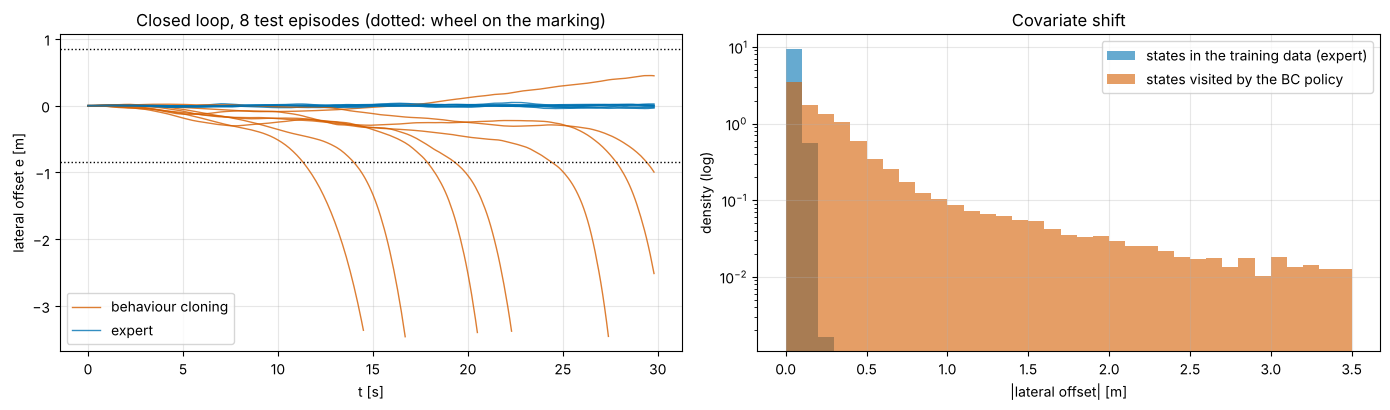

99.9 % of the training observations have |e| <= 0.17 m; 52% of the states visited by the BC policy lie beyond that, where the network has (almost) no data.


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
H_exp_test = rollout(expert, TEST_P, K_TEST, seed=2)
t = np.arange(N_STEPS - 1) * DT
for i in range(8):
    ax[0].plot(t, H_bc["e"][i], color=OI["red"], lw=1, alpha=0.8, label="behaviour cloning" if i == 0 else None)
    ax[0].plot(t, H_exp_test["e"][i], color=OI["blue"], lw=1, alpha=0.8, label="expert" if i == 0 else None)
for y in (LANE_HALF, -LANE_HALF):
    ax[0].axhline(y, color=OI["black"], ls=":", lw=1)
ax[0].set(xlabel="t [s]", ylabel="lateral offset e [m]", title="Closed loop, 8 test episodes (dotted: wheel on the marking)")
ax[0].legend()
bins = np.linspace(0, 3.5, 36)
ax[1].hist(np.abs(demo["obs"][:, 0]), bins=bins, density=True, alpha=0.6, color=OI["blue"], label="states in the training data (expert)")
ax[1].hist(np.abs(H_bc["e"][~np.isnan(H_bc["e"])]), bins=bins, density=True, alpha=0.6, color=OI["red"],
           label="states visited by the BC policy")
ax[1].set(yscale="log", xlabel="|lateral offset| [m]", ylabel="density (log)", title="Covariate shift")
ax[1].legend(); plt.tight_layout(); plt.show()
q_train = np.quantile(np.abs(demo["obs"][:, 0]), 0.999)
share_out = np.mean(np.abs(H_bc["e"][~np.isnan(H_bc["e"])]) > q_train)
print(f"99.9 % of the training observations have |e| <= {q_train:.2f} m; {share_out:.0%} of the states visited by "
      f"the BC policy lie beyond that, where the network has (almost) no data.")

The offline error is small, yet in closed loop the BC policy drifts out of its lane in many episodes and leaves the road in some. The histogram shows why: the expert keeps the car centred, so the training data contain almost no off-centre states. Once the learner's small steering errors accumulate, it is in a region where the network was never trained, and its corrections there are arbitrary. This is **covariate shift induced by the policy itself**, and it is invisible to any offline metric computed on expert data.

## 5. DAgger: let the expert label the learner's mistakes

DAgger (Dataset Aggregation; Ross et al., 2011) iterates: run the current policy (optionally mixed with the expert with probability $\beta$), ask the expert what it *would* have done in every visited state, add these labelled states to the data set, retrain. The data set thereby grows exactly where the learner goes. In industry the "expert" can be a human safety driver's interventions, a privileged planner in simulation, or an offline labelling process.

In [6]:
t_dag = time.time()
X, Y = demo["obs"], demo["labels"]
policy, rows = bc, [{"iteration": 0, "training pairs": len(X), **metrics(H_bc)}]
for it, beta in enumerate([0.5, 0.0, 0.0], start=1):
    H_tr = rollout(policy, TRAIN_P, K_TRAIN, beta=beta, seed=10 + it)       # roll out on TRAINING episodes
    X, Y = np.vstack([X, H_tr["obs"]]), np.vstack([Y, H_tr["labels"]])    # expert labels on visited states
    policy = fit(X, Y)
    rows.append({"iteration": it, "training pairs": len(X), **metrics(rollout(policy, TEST_P, K_TEST, seed=2))})
dagger = policy
dag = pd.DataFrame(rows).set_index("iteration")
display(dag[["training pairs", "road departures [%]", "episodes leaving the lane [%]", "mean max |e| [m]",
             "collisions [%]", "episodes with min TTC < 1.5 s [%]"]].round(2))
print(f"DAgger: {len(rows) - 1} iterations in {time.time() - t_dag:.0f} s. Episodes leaving the lane: "
      f"{dag.loc[0, 'episodes leaving the lane [%]']:.0f} % (BC) -> {dag.iloc[-1]['episodes leaving the lane [%]']:.0f} % "
      f"after iteration {dag.index[-1]}; road departures {dag.loc[0, 'road departures [%]']:.0f} % -> "
      f"{dag.iloc[-1]['road departures [%]']:.0f} %.")

,training pairs,road departures [%],episodes leaving the lane [%],mean max |e| [m],collisions [%],episodes with min TTC < 1.5 s [%]
iteration,,,,,,
0,18239,59.02,73.77,2.38,1.64,8.2
1,36478,39.34,52.46,1.79,0.00,0.0
2,53725,0.00,0.00,0.11,0.00,0.0
3,71964,0.00,0.00,0.13,0.00,0.0


DAgger: 3 iterations in 42 s. Episodes leaving the lane: 74 % (BC) -> 0 % after iteration 3; road departures 59 % -> 0 %.


Same network, same expert, same test episodes: only the *distribution* of the training data changed. Two points matter for a safety argument:

- **Data coverage must be argued over the states the deployed policy visits**, not over the states the demonstrator visited. ISO/PAS 8800 asks for dataset requirements derived from the AI safety requirements and the ODD; for a closed-loop policy, "recovery" states are part of that requirement.
- DAgger needs an expert who can be queried in the learner's states. Humans are poor at labelling states they are not controlling; simulation with a privileged planner is the usual substitute, which shifts the burden to simulation validity.

## 6. Causal confusion: more information, worse driving

de Haan et al. (2019) showed that giving an imitation learner *more* information can make it worse when the extra input is an **effect** of the expert's past actions rather than a cause of the next one. Their driving example is a dashboard brake indicator. We reproduce this with the longitudinal task (the expert steers): one learner sees the noisy perception outputs; a second learner additionally sees **its own previous acceleration** (equivalent to a brake-light or speedometer-trend cue in camera images). Because the expert's accelerations change slowly, the previous action predicts the next one very well in the training data.

We train both with three random seeds and compare an offline metric (RMSE against held-out expert labels) with closed-loop outcomes.

In [7]:
t_cc = time.time(); rows = []
for wp in (False, True):
    demo_l = rollout(expert, TRAIN_P, K_TRAIN, seed=1, with_prev=wp, lat_expert=True)
    val_l = rollout(expert, TEST_P, K_TEST, seed=3, with_prev=wp, lat_expert=True)
    for seed in (0, 1, 2):
        pol = fit(demo_l["obs"], demo_l["labels"], seed=seed, outputs=(0,))
        rmse = np.sqrt(((pol(val_l["obs"])[:, 0] - val_l["labels"][:, 0])**2).mean())
        m = metrics(rollout(pol, TEST_P, K_TEST, seed=2, with_prev=wp, lat_expert=True))
        rows.append({"inputs": "perception + own previous acceleration" if wp else "perception only", "seed": seed,
                     "offline RMSE [m/s^2]": rmse, "collisions [%]": m["collisions [%]"],
                     "episodes with min TTC < 1.5 s [%]": m["episodes with min TTC < 1.5 s [%]"],
                     "time RSS-unsafe [%]": m["time RSS-unsafe [%]"]})
        if wp and seed == 0:
            copycat = pol
        if not wp and seed == 0:
            percept = pol
cc = pd.DataFrame(rows)
display(cc.round(3))
g = cc.groupby("inputs").mean(numeric_only=True)
a_, b_ = g.loc["perception only"], g.loc["perception + own previous acceleration"]
print(f"{len(cc)} policies trained and driven in {time.time() - t_cc:.0f} s.")
print(f"Mean over seeds: offline RMSE {a_['offline RMSE [m/s^2]']:.3f} -> {b_['offline RMSE [m/s^2]']:.3f} m/s^2 "
      f"({'better' if b_['offline RMSE [m/s^2]'] < a_['offline RMSE [m/s^2]'] else 'worse'} with the extra input); "
      f"collisions {a_['collisions [%]']:.1f} % -> {b_['collisions [%]']:.1f} % "
      f"({'worse' if b_['collisions [%]'] > a_['collisions [%]'] else 'not worse'} with the extra input).")

,inputs,seed,offline RMSE [m/s^2],collisions [%],episodes with min TTC < 1.5 s [%],time RSS-unsafe [%]
0,perception only,0,0.290,0.000,1.639,37.628
1,perception only,1,0.288,0.000,1.639,38.138
2,perception only,2,0.289,0.000,1.639,29.124
3,perception + own previous acceleration,0,0.110,1.639,1.639,34.162
4,perception + own previous acceleration,1,0.110,4.918,8.197,47.243
5,perception + own previous acceleration,2,0.111,6.557,16.393,66.648


6 policies trained and driven in 21 s.
Mean over seeds: offline RMSE 0.289 -> 0.110 m/s^2 (better with the extra input); collisions 0.0 % -> 4.4 % (worse with the extra input).


The policy with the extra input looks **better** offline and drives **worse**. In the demonstrations, "keep doing what you just did" explains most of the expert's next action, so the network leans on it and pays less attention to the noisy gap and relative speed. In closed loop the previous action is its *own*: when the lead vehicle starts to brake, nothing in its recent behaviour says "brake", so it reacts late. The variation across seeds is itself a finding: the same architecture and data give very different closed-loop safety, which a single offline number hides.

Remedies discussed in the literature include removing or masking such inputs, targeted interventions to identify which inputs are causal (de Haan et al., 2019), and closed-loop training or evaluation. For a safety case the lesson is methodological: **offline imitation metrics are not evidence of closed-loop safety**, and the input set of a learned policy is a design decision that needs analysis (ISO/PAS 8800's safety analysis of AI errors).

## 7. A runtime shield around the learned policy

We now treat the learned policies as untrusted "complex controllers" and add a Simplex-style supervisor (see [07/02](../07_Runtime_Assurance_and_Operations/02_safe_motion_planning_and_fallback.ipynb)):

- **Longitudinal RSS shield.** If the perceived gap minus a margin of $2\sigma$ (3 m) is below $d_{\min}$ from `avsafety.sotif`, evaluated with a pessimistic lead speed ($v + \Delta v - 2\sigma_{\Delta v}$), the acceleration is limited to $-b_{\min} = -4$ m/s² (the RSS proper response); otherwise the policy's command passes.
- **Lateral Simplex monitor.** If the perceived lateral offset exceeds 0.4 m, the curvature command is replaced by a simple, verifiable lane-keeping law (the same linear feedback as the expert's) until the vehicle is back.

The monitor sees the **same noisy perception** as the policy. It does not need to understand the network; it needs an object-level interface (gap, relative speed, lateral offset). This is exactly the interface a monolithic end-to-end model does not provide by itself.

In [8]:
E_MAX = 0.4                       # lateral monitor threshold [m]
GAP_MARGIN = 2 * OBS_NOISE[4]     # 2 sigma of the gap measurement [m]
DV_MARGIN = 2 * OBS_NOISE[5]      # 2 sigma of the relative-speed measurement [m/s]

def shield(O, A):
    e, psi, kap, v, gap, dv = (O[:, i] for i in range(6))
    A = A.copy()
    v_lead_pess = np.maximum(v + dv - DV_MARGIN, 0.0)
    danger = gap - GAP_MARGIN < rss_dmin(v, v_lead_pess, **RSS)
    brake = danger & (A[:, 0] > -RSS["b_min_brake"])
    A[:, 0] = np.where(danger, np.minimum(A[:, 0], -RSS["b_min_brake"]), A[:, 0])
    off = np.abs(e) > E_MAX
    vv = np.maximum(v, 5.0)
    safe_k = np.clip(kap - (0.5 * e + 1.4 * vv * psi) / vv**2, -K_MAX, K_MAX)
    A[:, 1] = np.where(off, safe_k, A[:, 1])
    return A, brake * 1 + off * 2          # override code: 1 longitudinal, 2 lateral, 3 both

K_SHARP = np.array([road_curvature(9000 + i, k_amp=0.03) for i in range(len(TEST_P))])    # radii down to ~33 m
cases = {
    "BC policy": dict(policy=bc),
    "copycat policy (perception + previous acceleration)": dict(policy=copycat, with_prev=True, lat_expert=True),
    "DAgger policy, sharp curves (outside training range)": dict(policy=dagger, kappa=K_SHARP),
}
rows = []
for name, cfg in cases.items():
    kap = cfg.get("kappa", K_TEST)
    kw = dict(with_prev=cfg.get("with_prev", False), lat_expert=cfg.get("lat_expert", False), seed=2)
    for sh in (None, shield):
        m = metrics(rollout(cfg["policy"], TEST_P, kap, shield=sh, **kw))
        rows.append({"policy": name, "runtime shield": "on" if sh else "off", **m})
sh = pd.DataFrame(rows).set_index(["policy", "runtime shield"])
display(sh[["collisions [%]", "road departures [%]", "episodes leaving the lane [%]",
            "episodes with min TTC < 1.5 s [%]", "time RSS-unsafe [%]", "longitudinal overrides [%]",
            "lateral overrides [%]"]].round(1))

collisions [%]  \
policy                                             runtime shield                   
BC policy                                          off                        1.6   
                                                   on                         0.0   
copycat policy (perception + previous accelerat... off                        1.6   
                                                   on                         0.0   
DAgger policy, sharp curves (outside training r... off                        0.0   
                                                   on                         0.0   

                                                                   road departures [%]  \
policy                                             runtime shield                        
BC policy                                          off                            59.0   
                                                   on                              0.0   
copycat policy (perception + previous accelerat... off                             0.0   
                                                   on                              0.0   
DAgger policy, sharp curves (outside training r... off                             0.0   
                                                   on                              0.0   

                                                                   episodes leaving the lane [%]  \
policy                                             runtime shield                                  
BC policy                                          off                                      73.8   
                                                   on                                        0.0   
copycat policy (perception + previous accelerat... off                                       0.0   
                                                   on                                        0.0   
DAgger policy, sharp curves (outside training r... off                                      42.6   
                                                   on                                        0.0   

                                                                   episodes with min TTC < 1.5 s [%]  \
policy                                             runtime shield                                      
BC policy                                          off                                           8.2   
                                                   on                                            0.0   
copycat policy (perception + previous accelerat... off                                           1.6   
                                                   on                                            0.0   
DAgger policy, sharp curves (outside training r... off                                           0.0   
                                                   on                                            0.0   

                                                                   time RSS-unsafe [%]  \
policy                                             runtime shield                        
BC policy                                          off                            43.4   
                                                   on                              0.0   
copycat policy (perception + previous accelerat... off                            34.2   
                                                   on                              0.0   
DAgger policy, sharp curves (outside training r... off                            35.2   
                                                   on                              0.0   

                                                                   longitudinal overrides [%]  \
policy                                             runtime shield                               
BC policy                                          off                                    0.0   
                   

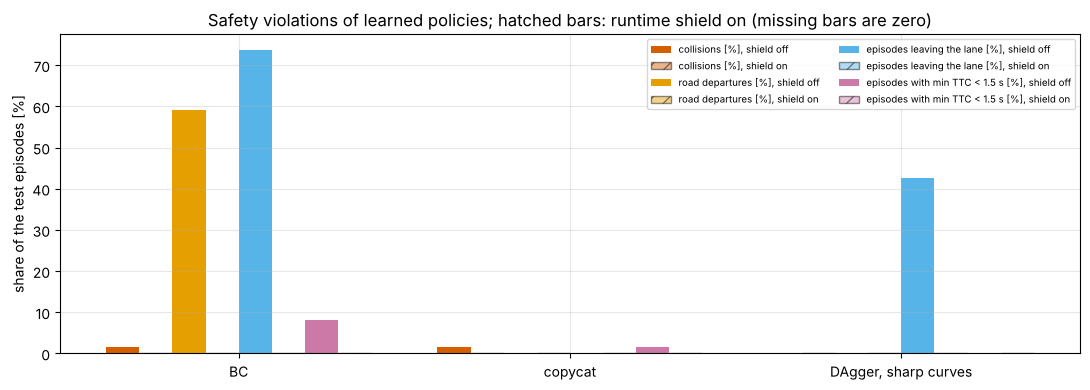

Text summary (computed from the table):
- BC policy: collisions 2 % -> 0 %, road departures 59 % -> 0 %, episodes leaving the lane 74 % -> 0 %, time RSS-unsafe 43 % -> 0 %; overrides: longitudinal 6 %, lateral 15 % of the time.
- copycat policy (perception + previous acceleration): collisions 2 % -> 0 %, road departures 0 % -> 0 %, episodes leaving the lane 0 % -> 0 %, time RSS-unsafe 34 % -> 0 %; overrides: longitudinal 1 %, lateral 0 % of the time.
- DAgger policy, sharp curves (outside training range): collisions 0 % -> 0 %, road departures 0 % -> 0 %, episodes leaving the lane 43 % -> 0 %, time RSS-unsafe 35 % -> 0 %; overrides: longitudinal 15 %, lateral 12 % of the time.


In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
cols = ["collisions [%]", "road departures [%]", "episodes leaving the lane [%]", "episodes with min TTC < 1.5 s [%]"]
xs = np.arange(len(cases))
w = 0.1
for j, (cname, col) in enumerate(zip(cols, [OI["red"], OI["orange"], OI["sky"], OI["purple"]])):
    off_v = [sh.loc[(n, "off"), cname] for n in cases]
    on_v = [sh.loc[(n, "on"), cname] for n in cases]
    ax.bar(xs + (2 * j - 3.5) * w, off_v, w, color=col, label=f"{cname}, shield off")
    ax.bar(xs + (2 * j - 2.5) * w, on_v, w, color=col, alpha=0.45, hatch="//", edgecolor=OI["black"], label=f"{cname}, shield on")
ax.set_xticks(xs, ["BC", "copycat", "DAgger, sharp curves"])
ax.set(ylabel="share of the test episodes [%]", title="Safety violations of learned policies; hatched bars: runtime shield on (missing bars are zero)")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

print("Text summary (computed from the table):")
for n in cases:
    off_, on_ = sh.loc[(n, "off")], sh.loc[(n, "on")]
    print(f"- {n}: collisions {off_['collisions [%]']:.0f} % -> {on_['collisions [%]']:.0f} %, road departures "
          f"{off_['road departures [%]']:.0f} % -> {on_['road departures [%]']:.0f} %, episodes leaving the lane "
          f"{off_['episodes leaving the lane [%]']:.0f} % -> {on_['episodes leaving the lane [%]']:.0f} %, time RSS-unsafe "
          f"{off_['time RSS-unsafe [%]']:.0f} % -> {on_['time RSS-unsafe [%]']:.0f} %; overrides: longitudinal "
          f"{on_['longitudinal overrides [%]']:.0f} %, lateral {on_['lateral overrides [%]']:.0f} % of the time.")

**What the shield does and does not do.**

- It removes most collisions and road departures *without retraining the network*, because it acts on a small set of physically meaningful quantities with a formally derived rule. That is the main argument for keeping such interfaces in learned stacks.
- It does not make the learned policy good. Look at the override rates: the longitudinal shield acts whenever the policy follows more closely than the RSS envelope allows, which, as the 'time RSS-unsafe' column without the shield shows, is common for an imitation of a human-like driver (Section 3). The safety controller is then driving a noticeable part of the time; in a product that is an availability and comfort problem, and override rates are **safety performance indicators** that should trigger investigation.
- It inherits the monitor's assumptions: the perception outputs it uses must be accurate to within the margins (here 2σ of a *known* noise model), the lead vehicle must not brake harder than $b_{\max}$, and the lateral monitor only protects against drift it can observe. A camera-only end-to-end model has no separate gap estimate; providing one (radar, a parallel perception path, structured outputs from the model itself) is an architectural decision with its own ISO 26262 and ISO 21448 obligations.
- Curves with radii down to about 33 m, when training only saw radii of 250 m and more, are a **distribution shift** for the DAgger policy, which was fine on the test roads (Section 5). The lateral monitor catches the resulting drift; it cannot tell *why* the policy failed, which is what the field-monitoring and data loop has to find out.

## 8. What the standards would need to see

| Evidence need | ISO/PAS 8800:2024 | ISO 21448:2022 | UL 4600 (3rd ed., 2023) |
|---|---|---|---|
| **Specification** | AI safety requirements for the AI system/element, expressed through measurable safety-related properties (e.g. closed-loop collision and lane-departure rates per ODD slice) | Specification of the intended functionality and acceptance criteria / validation targets for the residual risk | Claims and argument of the safety case for the item, including ML components |
| **Data** | Dataset requirements derived from the safety requirements and the ODD; coverage of the states the *deployed* policy visits (recovery data, DAgger-type collection); independence of test data | Triggering conditions in the data: which scenarios provoke functional insufficiencies | Evidence that training and validation data represent the ODD; argument about data gaps |
| **Analysis of AI errors** | Safety analysis of the AI element: covariate shift, causal confusion, shortcut learning, hallucination as error mechanisms with measures | Analysis of functional insufficiencies and triggering conditions for a function without intermediate interfaces, at the level of inputs to vehicle behaviour | Hazard log entries for ML-specific failure modes |
| **Verification and validation** | V&V of the AI system including **closed-loop** testing, robustness and generalisation checks; offline metrics alone are insufficient (Section 6) | Evaluation of known hazardous scenarios and search for unknown ones (simulation, proving ground, road); validation targets demonstrated statistically ([06/08](08_statistical_safety_validation.ipynb)) | Validation evidence, including simulation validity if world models or simulators are used as evidence |
| **Architectural measures** | Safety mechanisms around the AI element (monitors, shields, redundancy), with their own requirements | Measures that reduce the effect of insufficiencies (envelopes, ODD restriction, fallback) | The safety case must argue the monitor's assumptions and independence |
| **Operation** | Measures during operation: monitoring of the AI element, controlled retraining and release | Field monitoring for new triggering conditions | Safety performance indicators (e.g. shield-override rate, near misses) that keep the safety case valid |

The common thread: for a learned driving policy, most evidence moves from component tests to **closed-loop, system-level** evidence plus **runtime assurance**, and the argument about *which* states were covered becomes central.

## 9. Open problems (as of October 2026)

1. **Closed-loop evaluation at scale.** Open-loop benchmarks reward shortcuts (Zhai et al., 2023; Li et al., 2024); closed-loop simulation with realistic, reactive agents and sensor rendering is expensive and its validity has to be shown (Dauner et al., 2023, 2024).
2. **Generative world models as evidence.** Using models such as GAIA-1 or a driving foundation model to generate test scenarios raises the question of how to validate the generator itself, so that passing generated tests means something about the real world.
3. **Faithful explanations.** Language explanations of VLA models are attractive for transparency, but nothing guarantees that the explanation caused the action; hallucinated explanations can mislead reviewers and users.
4. **Monitors without interfaces.** Runtime assurance needs object-level quantities. Whether to require structured intermediate outputs from end-to-end models, run a parallel conventional perception path, or monitor at the sensor and action level is unresolved, and each choice has cost and common-cause implications.
5. **Coverage arguments for data.** For a policy, the relevant distribution depends on the policy itself (Section 4); quantitative arguments for "enough" data in a high-dimensional ODD remain open.
6. **Change management.** Large models are retrained often; showing that a new release does not reintroduce old failures (regression evidence, SPI monitoring) is an operational safety problem as much as a technical one.
7. **Standards coverage.** ISO/PAS 8800 mostly addresses supervised ML components; guidance for foundation models, VLA architectures and learned planners in automotive safety standards is still emerging.

## Limitations of this notebook

- The simulator is kinematic and one-dimensional per axis; the "end-to-end" policy maps low-dimensional perception outputs, not camera images, to actions. The mechanisms (covariate shift, causal confusion, shielding) are the same, but magnitudes do not transfer.
- The expert is a model (IDM plus a linear lateral law), not human data; the lead vehicles are real.
- Road curvature and noise levels are synthetic. Results vary with seeds; Section 6 shows this explicitly.
- The shield is evaluated with a known Gaussian perception-noise model. Real perception errors are heavier-tailed and correlated in time.

## In industry

**Work products fed.** The **AI safety requirements** and **dataset requirements** of ISO/PAS 8800 for a learned planner or end-to-end policy; the **safety analysis of AI errors** (covariate shift, causal confusion, shortcut learning); the **SOTIF triggering-condition analysis** and **validation report** for the driving function; the **runtime assurance concept** (monitor, shield, fallback) and its verification; the **safety case** with SPIs such as shield-override rate.

**Owner.** ML engineers own training and the data pipeline; a safety architect owns the monitor and its interface requirements; the SOTIF and AI-safety engineers own the error analysis and validation strategy; the V&V team owns closed-loop simulation and its validity argument; operations owns field monitoring and release decisions.

**Tools and formats.** Closed-loop simulators with reactive agents and logged-scenario replay; data-engine tooling to mine fleet logs for interventions and disagreements between policy and monitor; experiment tracking with frozen dataset manifests; SPI dashboards per software release.

**Typical review findings**
- Model release justified with open-loop metrics (displacement error, imitation loss) only.
- No analysis of which inputs the policy uses; history or ego-status inputs added without a causal-confusion check.
- Training data from expert driving only, no recovery data; coverage argued over the demonstrator's states.
- A runtime monitor that relies on outputs of the same network it is supposed to supervise (common cause).
- Language explanations presented as evidence of correct reasoning.

**What an assessor checks:** that closed-loop evidence exists per ODD slice with statistical confidence; that data coverage is argued for the deployed policy's state distribution; that the monitor's inputs are independent enough of the learned policy and its assumptions are monitored in operation; that override and near-miss SPIs have thresholds and owners; and that each retraining passes a defined regression suite before release.

## Key takeaways

- End-to-end and foundation-model approaches replace specified interfaces with learned representations; that removes the natural attachment points for requirements and monitors.
- **Behaviour cloning fails in closed loop** even with small offline error, because the policy drives itself into states the expert never showed; **DAgger** fixes this by labelling the learner's own states.
- **Causal confusion**: an input that is an effect of past actions (here, the previous acceleration) improved the offline metric and worsened closed-loop safety. Offline imitation metrics are not safety evidence.
- A **runtime shield** with an object-level interface and a formal rule (RSS) plus a simple lateral fallback removed most violations without touching the network, at the cost of overrides and with its own assumptions.
- Industry statements from Tesla, Wayve, NVIDIA and Waymo show the spread from "single end-to-end network" to "foundation model plus separate validation layer"; the safety argument looks very different for each.
- ISO/PAS 8800, ISO 21448 and UL 4600 together demand closed-loop evidence, data coverage for the deployed policy, analysis of AI-specific errors, independent runtime measures and SPIs in operation.

## Self-assessment

1. Why can a behaviour-cloned policy with a very small offline error leave the road in closed loop?
2. What does DAgger change, and why does it need an expert who can be queried?
3. Explain causal confusion using the previous-acceleration experiment. Why did the offline RMSE improve?
4. Name two reasons why open-loop planning benchmarks can reward shortcuts.
5. What does the runtime shield need from the driving stack, and why is this a problem for a camera-only end-to-end model?
6. Which ISO/PAS 8800 work products change most when the AI element is a driving policy rather than a perception component?
7. Why is a natural-language explanation from a VLA model weak evidence for a safety case?

<details>
<summary><b>Show answers</b></summary>

1. The offline error is measured on states from the expert's distribution. In closed loop, small errors accumulate and move the vehicle into states (off-centre, misaligned) that hardly occur in the training data, where the network's output is not constrained by data; errors then grow further (compounding error, covariate shift).
2. It collects data on the states the learner visits and labels them with the expert's action, so the training distribution matches the deployment distribution of the policy. Labels are needed for states the expert itself would not have reached, so the expert must be able to answer "what would you do here?", e.g. a planner with privileged information in simulation.
3. In the demonstrations the expert's acceleration changes slowly, so the previous acceleration predicts the next one well; the network uses it and relies less on the noisy gap and relative speed. Offline, with expert history, this is accurate. In closed loop the history is the learner's own, so it does not start braking when the lead brakes: the nuisance input is an effect of past actions, not a cause of the correct next action.
4. For example: the ego's own motion history extrapolates well over short horizons (ego-status shortcuts), and open-loop metrics never let errors compound because the logged expert state is restored at every step; they also ignore whether a plan would have caused a collision with reactive agents.
5. Object-level quantities (gap, relative speed, lateral position) with known accuracy. A camera-only end-to-end model may not expose them, so they must come from another path (radar, parallel perception, structured outputs), with its own requirements and independence argument.
6. Dataset requirements (coverage of the policy's own state distribution, recovery data), safety analysis of AI errors (covariate shift, causal confusion), and V&V (closed-loop testing per ODD slice instead of component metrics); plus operation-phase monitoring with SPIs such as override rates.
7. Nothing guarantees that the generated explanation reflects the computation that produced the action; language models can hallucinate plausible but wrong reasons. Explanations may help debugging, but evidence must come from testing and analysis of the behaviour itself.

</details>

## References

- Bojarski, M., Del Testa, D., Dworakowski, D., Firner, B., Flepp, B., et al. (2016). End to end learning for self-driving cars. arXiv:1604.07316. https://arxiv.org/abs/1604.07316
- Chen, L., Wu, P., Chitta, K., Jaeger, B., Geiger, A., Li, H. (2024). End-to-end autonomous driving: Challenges and frontiers. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 46(12), 10164–10183. https://doi.org/10.1109/TPAMI.2024.3435937
- Codevilla, F., Santana, E., López, A. M., Gaidon, A. (2019). Exploring the limitations of behavior cloning for autonomous driving. *ICCV 2019*, 9328–9337. https://doi.org/10.1109/ICCV.2019.00942
- Dauner, D., Hallgarten, M., Geiger, A., Chitta, K. (2023). Parting with misconceptions about learning-based vehicle motion planning. *CoRL 2023*. arXiv:2306.07962. https://arxiv.org/abs/2306.07962
- Dauner, D., Hallgarten, M., Li, T., Weng, X., Huang, Z., et al. (2024). NAVSIM: Data-driven non-reactive autonomous vehicle simulation and benchmarking. *NeurIPS 2024 Datasets and Benchmarks*. arXiv:2406.15349. https://arxiv.org/abs/2406.15349
- de Haan, P., Jayaraman, D., Levine, S. (2019). Causal confusion in imitation learning. *Advances in Neural Information Processing Systems 32 (NeurIPS 2019)*. arXiv:1905.11979. https://arxiv.org/abs/1905.11979
- Geirhos, R., Jacobsen, J.-H., Michaelis, C., Zemel, R., Brendel, W., Bethge, M., Wichmann, F. A. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence*, 2, 665–673. https://doi.org/10.1038/s42256-020-00257-z
- Hu, A., Russell, L., Yeo, H., Murez, Z., Fedoseev, G., et al. (2023). GAIA-1: A generative world model for autonomous driving. arXiv:2309.17080. https://arxiv.org/abs/2309.17080
- Hu, Y., Yang, J., Chen, L., Li, K., Sima, C., et al. (2023). Planning-oriented autonomous driving. *CVPR 2023*, 17853–17862. https://doi.org/10.1109/CVPR52729.2023.01712
- Hwang, J.-J., Xu, R., Lin, H., Hung, W.-C., Ji, J., et al. (2024). EMMA: End-to-end multimodal model for autonomous driving. arXiv:2410.23262 (accepted by TMLR). https://arxiv.org/abs/2410.23262
- ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence*. ISO 21448:2022. *Road vehicles — Safety of the intended functionality*. ISO/TS 5083:2025. *Road vehicles — Safety for automated driving systems — Design, verification and validation*. International Organization for Standardization.
- Ji, Z., Lee, N., Frieske, R., Yu, T., Su, D., et al. (2023). Survey of hallucination in natural language generation. *ACM Computing Surveys*, 55(12), 1–38. https://doi.org/10.1145/3571730
- Jiang, B., Chen, S., Xu, Q., Liao, B., Chen, J., et al. (2023). VAD: Vectorized scene representation for efficient autonomous driving. *ICCV 2023*, 8306–8316. https://doi.org/10.1109/ICCV51070.2023.00766
- Li, Z., Yu, Z., Lan, S., Li, J., Kautz, J., Lu, T., Alvarez, J. M. (2024). Is ego status all you need for open-loop end-to-end autonomous driving? *CVPR 2024*, 14864–14873. https://doi.org/10.1109/CVPR52733.2024.01408
- Not a Tesla App. Tesla software update 2023.44.30.10 (FSD Beta v12.1) release notes, dated 24 December 2023. https://www.notateslaapp.com/software-updates/version/2023.44.30.10/release-notes
- NVIDIA: Wang, Y., Luo, W., Bai, J., et al. (2025). Alpamayo-R1: Bridging reasoning and action prediction for generalizable autonomous driving in the long tail. arXiv:2511.00088. https://arxiv.org/abs/2511.00088
- Paden, B., Čáp, M., Yong, S. Z., Yershov, D., Frazzoli, E. (2016). A survey of motion planning and control techniques for self-driving urban vehicles. *IEEE Transactions on Intelligent Vehicles*, 1(1), 33–55. https://doi.org/10.1109/TIV.2016.2578706
- Pomerleau, D. A. (1988). ALVINN: An autonomous land vehicle in a neural network. *Advances in Neural Information Processing Systems 1 (NIPS 1988)*, 305–313. https://proceedings.neurips.cc/paper/1988/hash/812b4ba287f5ee0bc9d43bbf5bbe87fb-Abstract.html
- Rohrbach, A., Hendricks, L. A., Burns, K., Darrell, T., Saenko, K. (2018). Object hallucination in image captioning. *EMNLP 2018*, 4035–4045. https://doi.org/10.18653/v1/D18-1437
- Ross, S., Gordon, G. J., Bagnell, J. A. (2011). A reduction of imitation learning and structured prediction to no-regret online learning. *Proceedings of AISTATS 2011*, PMLR 15, 627–635. https://proceedings.mlr.press/v15/ross11a.html
- Shalev-Shwartz, S., Shammah, S., Shashua, A. (2017). On a formal model of safe and scalable self-driving cars. arXiv:1708.06374. https://arxiv.org/abs/1708.06374
- Sima, C., Renz, K., Chitta, K., Chen, L., Zhang, H., et al. (2024). DriveLM: Driving with graph visual question answering. *ECCV 2024*. arXiv:2312.14150. https://arxiv.org/abs/2312.14150
- Tian, X., Gu, J., Li, B., Liu, Y., Wang, Y., et al. (2024). DriveVLM: The convergence of autonomous driving and large vision-language models. arXiv:2402.12289. https://arxiv.org/abs/2402.12289
- Treiber, M., Hennecke, A., Helbing, D. (2000). Congested traffic states in empirical observations and microscopic simulations. *Physical Review E*, 62(2), 1805–1824. https://doi.org/10.1103/PhysRevE.62.1805
- UL 4600 (3rd ed., 2023). *Standard for Evaluation of Autonomous Products*. UL Standards & Engagement.
- US Department of Transportation, Federal Highway Administration. *Next Generation Simulation (NGSIM) Vehicle Trajectories and Supporting Data*, US-101 subset. Public domain. https://data.transportation.gov/d/8ect-6jqj
- Waymo AI Team (9 December 2025). Demonstrably safe AI for autonomous driving. Waymo blog. https://waymo.com/blog/2025/12/demonstrably-safe-ai-for-autonomous-driving
- Wayve (17 April 2024). LINGO-2: Driving with natural language. https://wayve.ai/thinking/lingo-2-driving-with-language/
- Zhai, J.-T., Feng, Z., Du, J., Mao, Y., Liu, J.-J., et al. (2023). Rethinking the open-loop evaluation of end-to-end autonomous driving in nuScenes. arXiv:2305.10430. https://arxiv.org/abs/2305.10430

In [10]:
print(f"Notebook executed in {time.time() - T0:.0f} s.")

Notebook executed in 72 s.


---
**Navigation:** ← [06 Explainability](06_explainability.ipynb) · [Module index](README.md) · [08 Statistical safety validation](08_statistical_safety_validation.ipynb) →